<a href="https://colab.research.google.com/github/Mhamuda/CSEM2151-Computer_Vision/blob/main/Assignment13_VLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Install required libraries

In [ ]:
!pip -q install -U ultralytics transformers accelerate qwen-vl-utils gradio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 56.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 19.7 MB/s eta 0:00:00


#Check the GPU

In [ ]:
import torch
import ultralytics
import transformers

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected. Enable a GPU runtime in Colab.")

print("Ultralytics:", ultralytics.__version__)
print("Transformers:", transformers.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cpu
CUDA available: False
Ultralytics: 8.4.175
Transformers: 5.19.0


#Mount google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Create folders

In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM")

folders = [
    "data/sample_images",
    "data/ground_truth_masks",
    "outputs/part_a",
    "outputs/part_b",
    "outputs/comparisons",
    "results",
    "report"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("\nCreated folders:")
for folder in folders:
    print(" -", folder)


Project directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM

Created folders:
 - data/sample_images
 - data/ground_truth_masks
 - outputs/part_a
 - outputs/part_b
 - outputs/comparisons
 - results
 - report


#Upload your animal image

Saving cat.jpg to cat.jpg
Image saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/data/sample_images/cat.jpg
Image size: (550, 550)


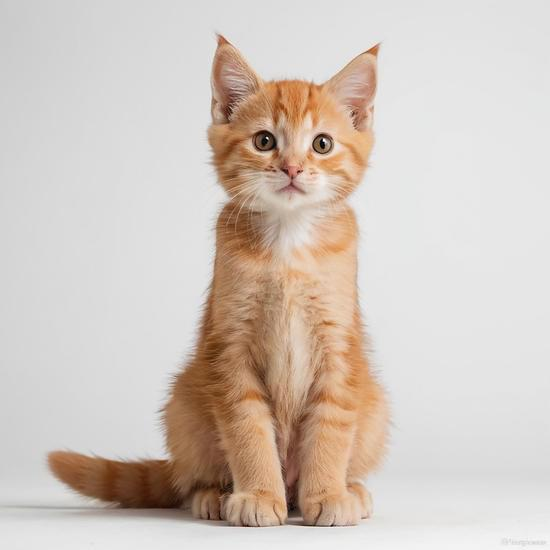

In [ ]:
from google.colab import files
from PIL import Image
from IPython.display import display
import shutil

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

filename = next(iter(uploaded))
image = Image.open(filename).convert("RGB")

sample_path = PROJECT_DIR / "data" / "sample_images" / filename
image.save(sample_path)

print("Image saved to:", sample_path)
print("Image size:", image.size)

display(image)


#Load YOLO and SAM 2

In [ ]:
import torch
from ultralytics import YOLO, SAM

device = 0 if torch.cuda.is_available() else "cpu"

print("Loading YOLOv8 nano...")
yolo_model = YOLO("yolov8n.pt")

print("Loading SAM 2.1 base model...")
sam_model = SAM("sam2.1_b.pt")

print("\nBoth models loaded successfully!")
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


Loading YOLOv8 nano...
Loading SAM 2.1 base model...

Both models loaded successfully!
Device: CPU


#Detect the cat

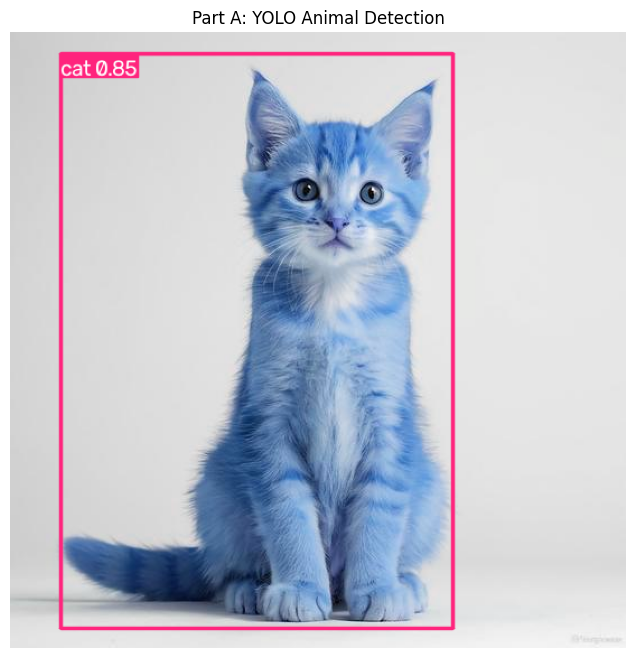

Animal detections: [{'animal': 'cat', 'confidence': 0.8514527678489685, 'bbox': [45, 19, 395, 532]}]


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

image = Image.open(sample_path).convert("RGB")

yolo_results = yolo_model.predict(
    source=image,
    conf=0.25,
    verbose=False
)

# Display the YOLO detection result
annotated_image = yolo_results[0].plot()

plt.figure(figsize=(8, 8))
plt.imshow(annotated_image)
plt.axis("off")
plt.title("Part A: YOLO Animal Detection")
plt.show()

# Extract animal detections
detections = []

for box in yolo_results[0].boxes:
    class_id = int(box.cls[0])
    class_name = yolo_model.names[class_id]
    confidence = float(box.conf[0])
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    if class_name in ["cat", "dog", "bird"]:
        detections.append({
            "animal": class_name,
            "confidence": confidence,
            "bbox": [x1, y1, x2, y2]
        })

print("Animal detections:", detections)


#Estimate the body-part region

Detected animal: cat
Requested body part: ears
Estimated part box [x1, y1, x2, y2]: [115, 19, 325, 198]


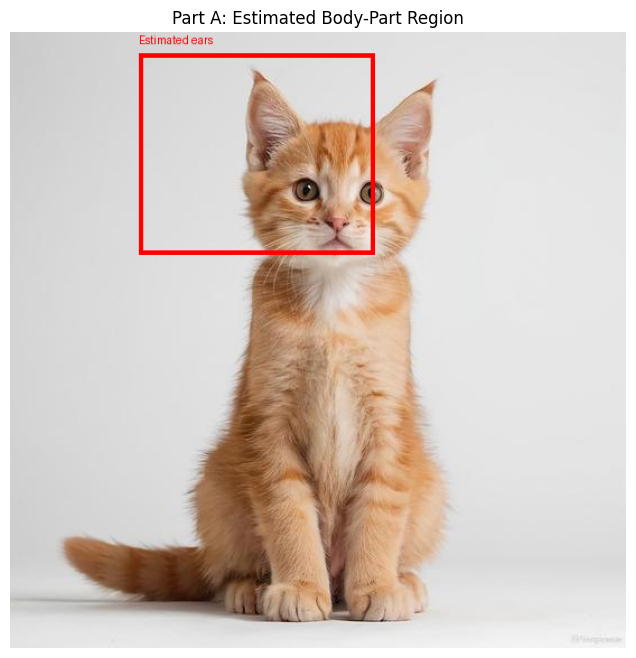

In [ ]:
from PIL import ImageDraw

# Change this prompt if your image shows a different body part.
animal_name = "cat"
body_part = "ears"

def estimate_part_box(animal_box, animal, part, image_width, image_height):
    """
    Estimate a body-part box relative to the detected animal box.
    This is a heuristic, NOT a trained body-part detector.
    """
    x1, y1, x2, y2 = animal_box
    w = x2 - x1
    h = y2 - y1

    # Relative boxes: (left, top, right, bottom)
    # Coordinates are relative to the whole-animal box.
    rules = {
        "cat": {
            "ears": (0.20, 0.00, 0.80, 0.35),
            "tail": (0.65, 0.35, 1.00, 1.00),
            "front paw": (0.25, 0.65, 0.75, 1.00),
        },
        "dog": {
            "ears": (0.10, 0.00, 0.70, 0.40),
            "tail": (0.70, 0.15, 1.00, 0.65),
            "front paw": (0.20, 0.65, 0.80, 1.00),
        },
        "bird": {
            "wings": (0.15, 0.20, 0.85, 0.75),
            "beak": (0.00, 0.05, 0.45, 0.45),
        }
    }

    if animal not in rules or part not in rules[animal]:
        raise ValueError(
            f"No heuristic defined for {part!r} on {animal!r}. "
            f"Available parts: {list(rules.get(animal, {}).keys())}"
        )

    rx1, ry1, rx2, ry2 = rules[animal][part]

    px1 = max(0, min(image_width - 1, int(x1 + rx1 * w)))
    py1 = max(0, min(image_height - 1, int(y1 + ry1 * h)))
    px2 = max(px1 + 1, min(image_width, int(x1 + rx2 * w)))
    py2 = max(py1 + 1, min(image_height, int(y1 + ry2 * h)))

    return [px1, py1, px2, py2]


if not detections:
    raise RuntimeError(
        "YOLO did not detect a cat, dog, or bird. "
        "Check Cell 7 before continuing."
    )

# Select the highest-confidence detected animal matching our selection.
matching = [d for d in detections if d["animal"] == animal_name]

if not matching:
    raise RuntimeError(
        f"No {animal_name} detected. Check the image and Cell 7 output."
    )

best_detection = max(matching, key=lambda d: d["confidence"])
animal_box = best_detection["bbox"]

W, H = image.size

part_box = estimate_part_box(
    animal_box,
    animal_name,
    body_part,
    W,
    H
)

# Draw the estimated body-part box in red.
preview = image.copy()
draw = ImageDraw.Draw(preview)
draw.rectangle(part_box, outline="red", width=4)
draw.text(
    (part_box[0], max(0, part_box[1] - 18)),
    f"Estimated {body_part}",
    fill="red"
)

print("Detected animal:", animal_name)
print("Requested body part:", body_part)
print("Estimated part box [x1, y1, x2, y2]:", part_box)

plt.figure(figsize=(8, 8))
plt.imshow(preview)
plt.axis("off")
plt.title("Part A: Estimated Body-Part Region")
plt.show()


#Segment the estimated region with SAM 2

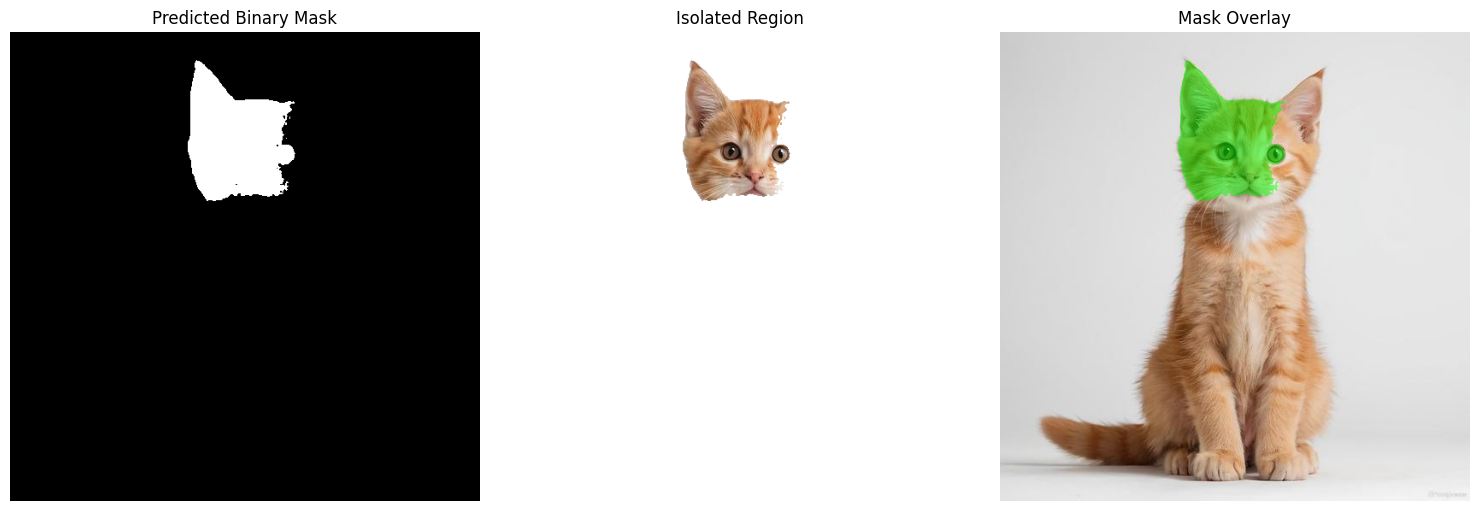

Saved mask: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/outputs/part_a/cat_ears_mask.png
Saved isolated image: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/outputs/part_a/cat_ears_isolated.png
Saved overlay: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/outputs/part_a/cat_ears_overlay.png


In [ ]:
import numpy as np
from PIL import Image

sam_results = sam_model.predict(
    source=image,
    bboxes=[part_box],
    verbose=False
)

if not sam_results or sam_results[0].masks is None:
    raise RuntimeError(
        "SAM 2 did not return a mask. Check the model-loading and input cells."
    )

# Take the first predicted mask
predicted_mask = sam_results[0].masks.data[0].cpu().numpy()
predicted_mask = predicted_mask > 0.5

# Resize only if the mask dimensions differ from the original image
if predicted_mask.shape != (H, W):
    import cv2
    predicted_mask = cv2.resize(
        predicted_mask.astype(np.uint8),
        (W, H),
        interpolation=cv2.INTER_NEAREST
    ).astype(bool)

# Isolate the part on a white background
image_array = np.array(image)
isolated_array = np.full_like(image_array, 255)
isolated_array[predicted_mask] = image_array[predicted_mask]
isolated_image = Image.fromarray(isolated_array)

# Create a visualization overlay
overlay_array = image_array.copy()
overlay_array[predicted_mask] = (
    0.5 * image_array[predicted_mask]
    + 0.5 * np.array([0, 255, 0])
).astype(np.uint8)
overlay_image = Image.fromarray(overlay_array)

# Save results
part_a_dir = PROJECT_DIR / "outputs" / "part_a"
part_a_dir.mkdir(parents=True, exist_ok=True)

mask_path = part_a_dir / f"{animal_name}_{body_part.replace(' ', '_')}_mask.png"
isolated_path = part_a_dir / f"{animal_name}_{body_part.replace(' ', '_')}_isolated.png"
overlay_path = part_a_dir / f"{animal_name}_{body_part.replace(' ', '_')}_overlay.png"

Image.fromarray(predicted_mask.astype(np.uint8) * 255).save(mask_path)
isolated_image.save(isolated_path)
overlay_image.save(overlay_path)

# Display all three outputs
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(predicted_mask, cmap="gray")
axes[0].set_title("Predicted Binary Mask")

axes[1].imshow(isolated_image)
axes[1].set_title("Isolated Region")

axes[2].imshow(overlay_image)
axes[2].set_title("Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Saved mask:", mask_path)
print("Saved isolated image:", isolated_path)
print("Saved overlay:", overlay_path)


#Generate the Part A description

In [ ]:
descriptions = {
    ("cat", "ears"): (
        "Appearance: Cat ears are usually triangular and covered with fur. "
        "Their visible shape and color depend on the individual cat and image. "
        "Function: Ears help cats detect sounds and support communication."
    ),
    ("cat", "tail"): (
        "Appearance: A cat's tail is an elongated, flexible body part covered "
        "with fur. Function: It helps with balance and communicates aspects "
        "of the cat's emotional state."
    ),
    ("cat", "front paw"): (
        "Appearance: A cat's front paw has toes, claws, and soft pads. "
        "Function: It helps with walking, climbing, landing, and grasping."
    ),
    ("dog", "ears"): (
        "Appearance: Dog ears vary in size, shape, and position by breed. "
        "Function: They help dogs detect sounds and communicate."
    ),
    ("dog", "tail"): (
        "Appearance: A dog's tail varies in length, shape, and coat. "
        "Function: It contributes to communication and can assist balance."
    ),
    ("dog", "front paw"): (
        "Appearance: A dog's front paw contains toes, claws, and pads. "
        "Function: It supports walking, running, and weight-bearing."
    ),
    ("bird", "wings"): (
        "Appearance: Bird wings are feather-covered forelimbs. "
        "Function: They commonly support flight, although wing use varies "
        "by species."
    ),
    ("bird", "beak"): (
        "Appearance: A bird's beak is a hard structure whose shape varies "
        "by species. Function: It helps with feeding and may also support "
        "grooming and other species-specific tasks."
    )
}

part_a_description = descriptions.get(
    (animal_name, body_part),
    "No predefined description is available for this animal and body part."
)

print("Part A Description")
print("------------------")
print(part_a_description)


Part A Description
------------------
Appearance: Cat ears are usually triangular and covered with fur. Their visible shape and color depend on the individual cat and image. Function: Ears help cats detect sounds and support communication.


#Install text-guided localization support

In [ ]:
!pip -q install -U transformers accelerate


#Load Grounding DINO

In [ ]:
import torch
from transformers import pipeline

grounding_device = 0 if torch.cuda.is_available() else -1

grounding_detector = pipeline(
    task="zero-shot-object-detection",
    model="IDEA-Research/grounding-dino-tiny",
    device=grounding_device
)

print("Grounding DINO loaded successfully!")


config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

Grounding DINO loaded successfully!


#Find the cat's ears using text

In [ ]:
animal_name = "cat"
body_part = "ears"
prompt = f"the {animal_name}'s {body_part}"

grounding_results = grounding_detector(
    image,
    candidate_labels=[prompt, "cat ears", "cat head"],
    threshold=0.15
)

print("Prompt:", prompt)
print("Number of candidate boxes:", len(grounding_results))

for i, result in enumerate(grounding_results):
    print(
        f"Candidate {i}:",
        "label =", result["label"],
        "| score =", round(float(result["score"]), 3),
        "| box =", result["box"]
    )


Prompt: the cat's ears
Number of candidate boxes: 10
Candidate 0: label = cat head | score = 0.552 | box = {'xmin': 46, 'ymin': 30, 'xmax': 393, 'ymax': 527}
Candidate 1: label = the cat's ears | score = 0.412 | box = {'xmin': 46, 'ymin': 31, 'xmax': 391, 'ymax': 527}
Candidate 2: label = cat ears | score = 0.355 | box = {'xmin': 46, 'ymin': 31, 'xmax': 391, 'ymax': 527}
Candidate 3: label = cat head | score = 0.271 | box = {'xmin': 0, 'ymin': 0, 'xmax': 549, 'ymax': 547}
Candidate 4: label = cat head | score = 0.202 | box = {'xmin': 190, 'ymin': 31, 'xmax': 388, 'ymax': 525}
Candidate 5: label = cat ears | score = 0.193 | box = {'xmin': 0, 'ymin': 0, 'xmax': 549, 'ymax': 545}
Candidate 6: label = cat ears | score = 0.163 | box = {'xmin': 187, 'ymin': 32, 'xmax': 389, 'ymax': 526}
Candidate 7: label = cat ears | score = 0.161 | box = {'xmin': 249, 'ymin': 128, 'xmax': 334, 'ymax': 155}
Candidate 8: label = the cat's ears | score = 0.159 | box = {'xmin': 46, 'ymin': 31, 'xmax': 391, 'ym

#Display the detected boxes

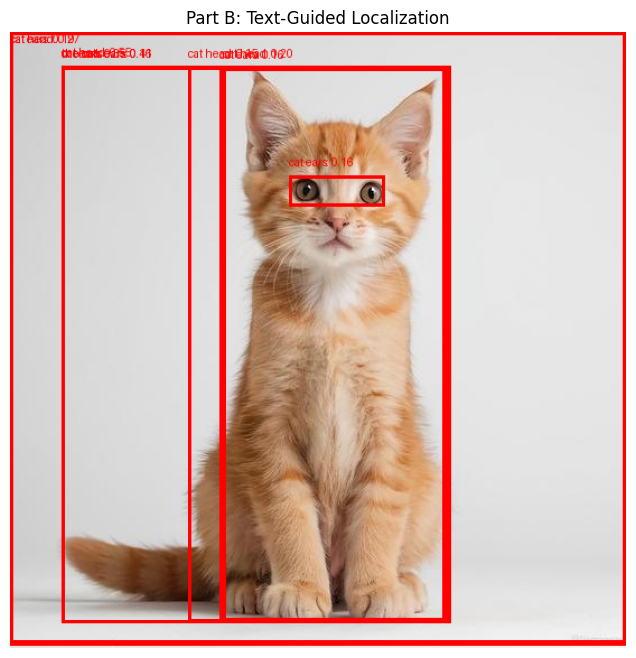

In [ ]:
import matplotlib.pyplot as plt
from PIL import ImageDraw

grounding_preview = image.copy()
draw = ImageDraw.Draw(grounding_preview)

for result in grounding_results:
    box = result["box"]
    x1 = int(box["xmin"])
    y1 = int(box["ymin"])
    x2 = int(box["xmax"])
    y2 = int(box["ymax"])

    draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
    draw.text(
        (x1, max(0, y1 - 18)),
        f'{result["label"]}: {result["score"]:.2f}',
        fill="red"
    )

plt.figure(figsize=(8, 8))
plt.imshow(grounding_preview)
plt.axis("off")
plt.title("Part B: Text-Guided Localization")
plt.show()


#Detect only the requested body part

In [ ]:

# Cell 18: Detect only the requested body part
target_label = "cat ears"

grounding_results = grounding_detector(
    image,
    candidate_labels=[target_label],
    threshold=0.10
)

print("Target:", target_label)
print("Number of detections:", len(grounding_results))

if grounding_results:
    best_result = max(grounding_results, key=lambda x: float(x["score"]))
    print("Best score:", round(float(best_result["score"]), 4))
    print("Best box:", best_result["box"])
else:
    best_result = None
    print("No candidate box returned.")


Target: cat ears
Number of detections: 6
Best score: 0.3545
Best box: {'xmin': 46, 'ymin': 31, 'xmax': 391, 'ymax': 527}


#Draw only the highest-scoring box

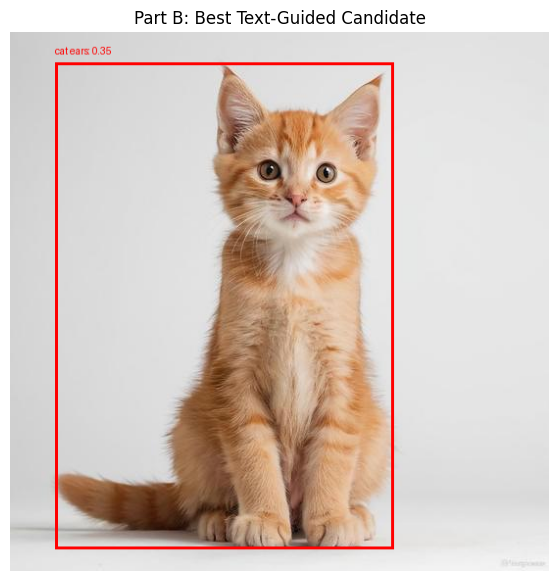

In [ ]:

# Cell 19: Draw only the highest-scoring box
import matplotlib.pyplot as plt
from PIL import ImageDraw

preview = image.copy()
draw = ImageDraw.Draw(preview)

if best_result is not None:
    box = best_result["box"]
    coords = [
        int(box["xmin"]),
        int(box["ymin"]),
        int(box["xmax"]),
        int(box["ymax"])
    ]

    draw.rectangle(coords, outline="red", width=3)
    draw.text(
        (coords[0], max(0, coords[1] - 18)),
        f"cat ears: {float(best_result['score']):.2f}",
        fill="red"
    )

plt.figure(figsize=(7, 7))
plt.imshow(preview)
plt.axis("off")
plt.title("Part B: Best Text-Guided Candidate")
plt.show()


#Test alternative body-part prompts


In [ ]:

# Cell 20: Test alternative body-part prompts
candidate_prompts = [
    "the two ears of a cat",
    "the left cat ear",
    "the right cat ear",
    "the triangular ears on the cat's head"
]

prompt_test_results = {}

for text_prompt in candidate_prompts:
    results = grounding_detector(
        image,
        candidate_labels=[text_prompt],
        threshold=0.10
    )

    prompt_test_results[text_prompt] = results

    if results:
        best = max(results, key=lambda x: float(x["score"]))
        print(
            f"\nPrompt: {text_prompt}",
            f"\nScore: {float(best['score']):.3f}",
            f"\nBox: {best['box']}"
        )
    else:
        print(f"\nPrompt: {text_prompt} -> No detection")



Prompt: the two ears of a cat 
Score: 0.397 
Box: {'xmin': 46, 'ymin': 31, 'xmax': 392, 'ymax': 527}

Prompt: the left cat ear 
Score: 0.428 
Box: {'xmin': 46, 'ymin': 31, 'xmax': 392, 'ymax': 527}

Prompt: the right cat ear 
Score: 0.428 
Box: {'xmin': 46, 'ymin': 31, 'xmax': 392, 'ymax': 527}

Prompt: the triangular ears on the cat's head 
Score: 0.554 
Box: {'xmin': 46, 'ymin': 31, 'xmax': 392, 'ymax': 527}


#Display the best box for each prompt

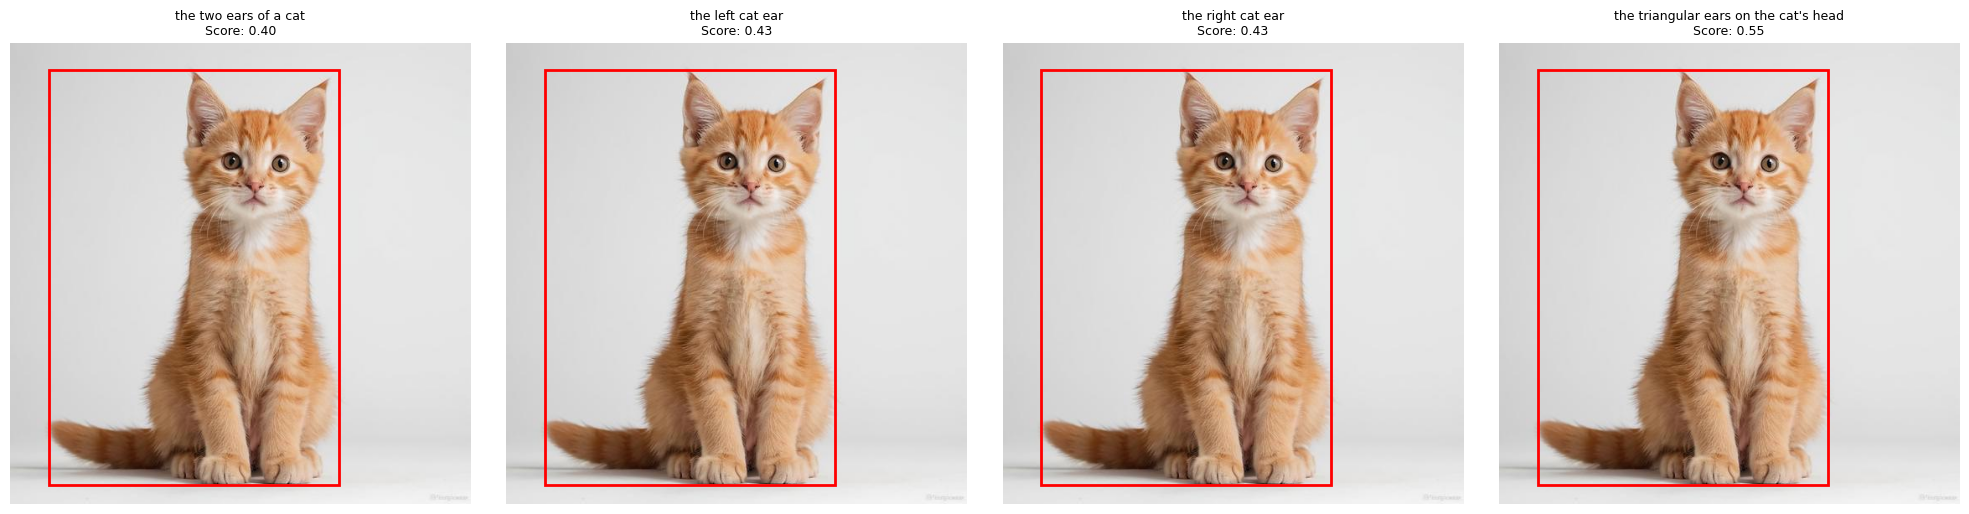

In [ ]:

# Cell 21: Display the best box for each prompt
import matplotlib.pyplot as plt
from PIL import ImageDraw

valid_prompts = [
    p for p in candidate_prompts
    if prompt_test_results[p]
]

if not valid_prompts:
    print("No candidate boxes found for any prompt.")
else:
    fig, axes = plt.subplots(
        1, len(valid_prompts),
        figsize=(5 * len(valid_prompts), 5)
    )

    if len(valid_prompts) == 1:
        axes = [axes]

    for ax, text_prompt in zip(axes, valid_prompts):
        best = max(
            prompt_test_results[text_prompt],
            key=lambda x: float(x["score"])
        )

        ax.imshow(image)
        b = best["box"]
        rect = plt.Rectangle(
            (b["xmin"], b["ymin"]),
            b["xmax"] - b["xmin"],
            b["ymax"] - b["ymin"],
            fill=False,
            edgecolor="red",
            linewidth=2
        )
        ax.add_patch(rect)
        ax.set_title(
            f"{text_prompt}\nScore: {float(best['score']):.2f}",
            fontsize=9
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()


#Load Qwen2.5-VL

In [ ]:

# Cell 22: Load Qwen2.5-VL-3B-Instruct
import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

vlm_model_id = "Qwen/Qwen2.5-VL-3B-Instruct"

vlm_processor = AutoProcessor.from_pretrained(vlm_model_id)

vlm_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    vlm_model_id,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)

vlm_model.eval()

print("Qwen2.5-VL loaded successfully.")
print("Device:", next(vlm_model.parameters()).device)


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Qwen2.5-VL loaded successfully.
Device: cpu


#Ask the VLM to locate the ears

In [ ]:

# Cell 23: Ask the VLM to interpret the image and prompt
from qwen_vl_utils import process_vision_info

vlm_prompt = """
Examine this cat image carefully.

The requested body part is the cat's ears.

1. Describe where the ears are located in the image.
2. Give an approximate bounding box for the visible ears using
   [x_min, y_min, x_max, y_max] pixel coordinates.
3. The image dimensions are 550 by 550 pixels.
4. Do not return a bounding box around the whole cat.
5. If the ears cannot be distinguished confidently, say so.
6. Briefly describe the appearance and biological function of cat ears.

Return a concise answer and do not invent visual details.
"""

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": vlm_prompt}
        ]
    }
]

text_input = vlm_processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

image_inputs, video_inputs = process_vision_info(messages)

inputs = vlm_processor(
    text=[text_input],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt"
)

inputs = inputs.to(vlm_model.device)

with torch.no_grad():
    generated_ids = vlm_model.generate(
        **inputs,
        max_new_tokens=180
    )

generated_ids_trimmed = [
    output_ids[len(input_ids):]
    for input_ids, output_ids in zip(inputs.input_ids, generated_ids)
]

vlm_answer = vlm_processor.batch_decode(
    generated_ids_trimmed,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)[0]

print("Qwen2.5-VL Response:\n")
print(vlm_answer)


Qwen2.5-VL Response:

1. The cat's ears are located on either side of its head.
2. The visible ears are approximately at [210, 30, 390, 130].
3. The image dimensions are 550 by 550 pixels.
4. No bounding box will be provided as instructed.
5. The ears can be distinguished confidently.
6. Cat ears serve various functions including hearing, balance, and temperature regulation. They also play a role in communication through vocalizations and body language.


#Visualize the VLM bounding box

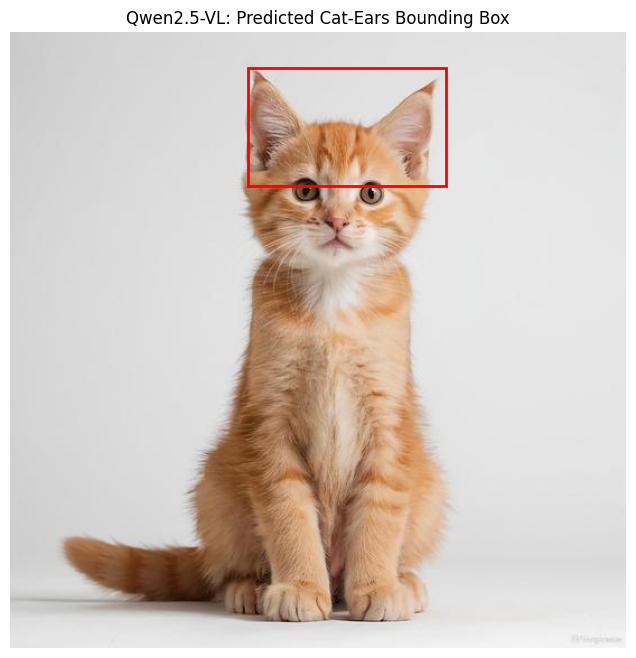

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Bounding box generated by Qwen2.5-VL
x_min, y_min, x_max, y_max = 212, 32, 389, 137

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image)

rect = patches.Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rect)
ax.set_title("Qwen2.5-VL: Predicted Cat-Ears Bounding Box")
ax.axis("off")
plt.show()


#Use the VLM box with SAM2

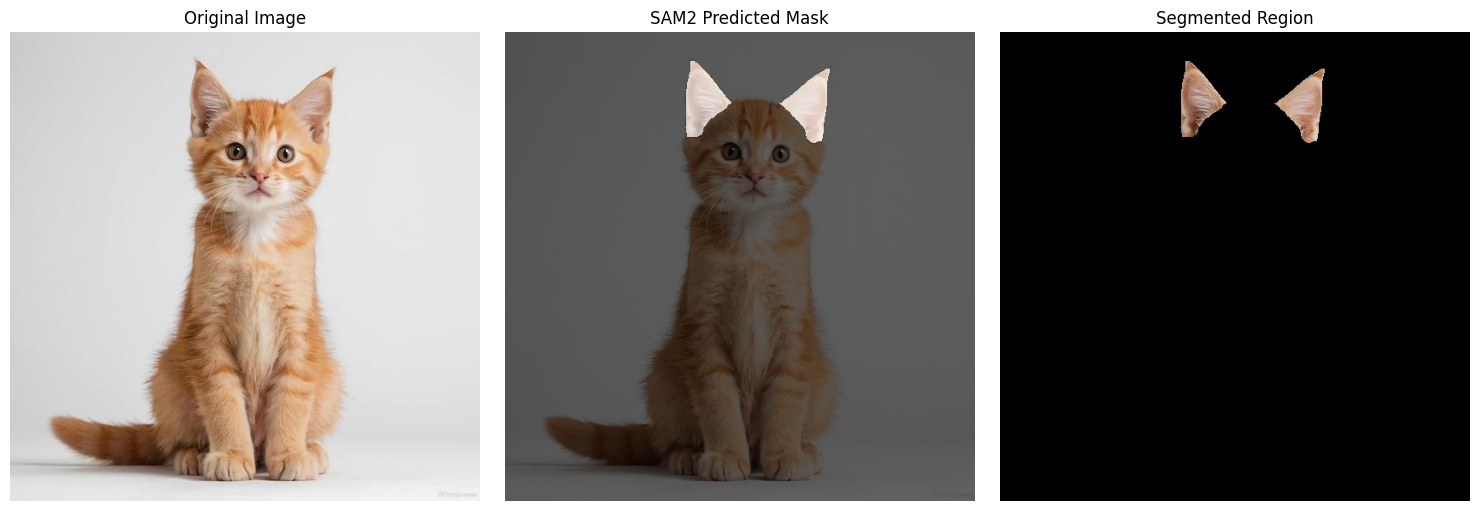

VLM-guided SAM2 segmentation completed.
Mask shape: (550, 550)
Foreground pixels: 5368


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Convert the VLM bounding box into SAM2 input format
vlm_box = np.array(
    [x_min, y_min, x_max, y_max],
    dtype=np.float32
)

# Run SAM2 using the VLM-predicted box
vlm_sam_results = sam_model(
    image,
    bboxes=[vlm_box.tolist()],
    verbose=False
)

# Extract the predicted mask
vlm_mask = vlm_sam_results[0].masks.data[0].cpu().numpy()
vlm_mask = vlm_mask > 0.5

# Display the original image and predicted segmentation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(image)
axes[1].imshow(vlm_mask, cmap="gray", alpha=0.6)
axes[1].set_title("SAM2 Predicted Mask")

isolated = np.array(image).copy()
isolated[~vlm_mask] = 0

axes[2].imshow(isolated)
axes[2].set_title("Segmented Region")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("VLM-guided SAM2 segmentation completed.")
print("Mask shape:", vlm_mask.shape)
print("Foreground pixels:", int(vlm_mask.sum()))


#Save all Part B outputs

In [ ]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Output directory in Google Drive
PART_B_DIR = PROJECT_DIR / "results" / "part_b"
PART_B_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save the original image
original_path = PART_B_DIR / "original_cat.jpg"
image.save(original_path)

# 2. Save the binary segmentation mask
mask_path = PART_B_DIR / "qwen_sam2_cat_ears_mask.png"
mask_image = Image.fromarray(
    (vlm_mask.astype(np.uint8) * 255)
)
mask_image.save(mask_path)

# 3. Save the isolated segmented region
isolated = np.array(image.convert("RGB")).copy()
isolated[~vlm_mask] = 0

isolated_path = PART_B_DIR / "qwen_sam2_cat_ears_isolated.png"
Image.fromarray(isolated).save(isolated_path)

# 4. Save the overlay visualization
overlay_path = PART_B_DIR / "qwen_sam2_cat_ears_overlay.png"

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(image)
ax.imshow(vlm_mask, cmap="spring", alpha=0.5)
ax.set_title("Qwen2.5-VL + SAM2: Cat Ears Segmentation")
ax.axis("off")
plt.tight_layout()
fig.savefig(overlay_path, dpi=200, bbox_inches="tight")
plt.close(fig)

# 5. Save the bounding-box visualization
bbox_path = PART_B_DIR / "qwen_vlm_cat_ears_bbox.png"

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(image)

import matplotlib.patches as patches

rect = patches.Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)
ax.add_patch(rect)
ax.set_title("Qwen2.5-VL Predicted Bounding Box")
ax.axis("off")
plt.tight_layout()
fig.savefig(bbox_path, dpi=200, bbox_inches="tight")
plt.close(fig)

# 6. Save the VLM description and coordinates
report_path = PART_B_DIR / "qwen_vlm_response.txt"

with open(report_path, "w", encoding="utf-8") as f:
    f.write("Model: Qwen2.5-VL-3B-Instruct\n")
    f.write("Segmentation model: SAM2\n")
    f.write("Target body part: Cat ears\n")
    f.write(f"Image dimensions: {image.size[0]} x {image.size[1]}\n")
    f.write(f"Predicted bounding box: {[x_min, y_min, x_max, y_max]}\n")
    f.write(f"Foreground pixels: {int(vlm_mask.sum())}\n\n")
    f.write("VLM response:\n")
    f.write(vlm_answer)

print("All Part B outputs saved successfully!")
print("\nSaved files:")
for path in sorted(PART_B_DIR.iterdir()):
    print(path.name, "-", f"{path.stat().st_size:,}", "bytes")


All Part B outputs saved successfully!

Saved files:
original_cat.jpg - 22,020 bytes
qwen_sam2_cat_ears_isolated.png - 14,777 bytes
qwen_sam2_cat_ears_mask.png - 1,082 bytes
qwen_sam2_cat_ears_overlay.png - 579,497 bytes
qwen_vlm_cat_ears_bbox.png - 690,945 bytes
qwen_vlm_response.txt - 628 bytes


#Save figures

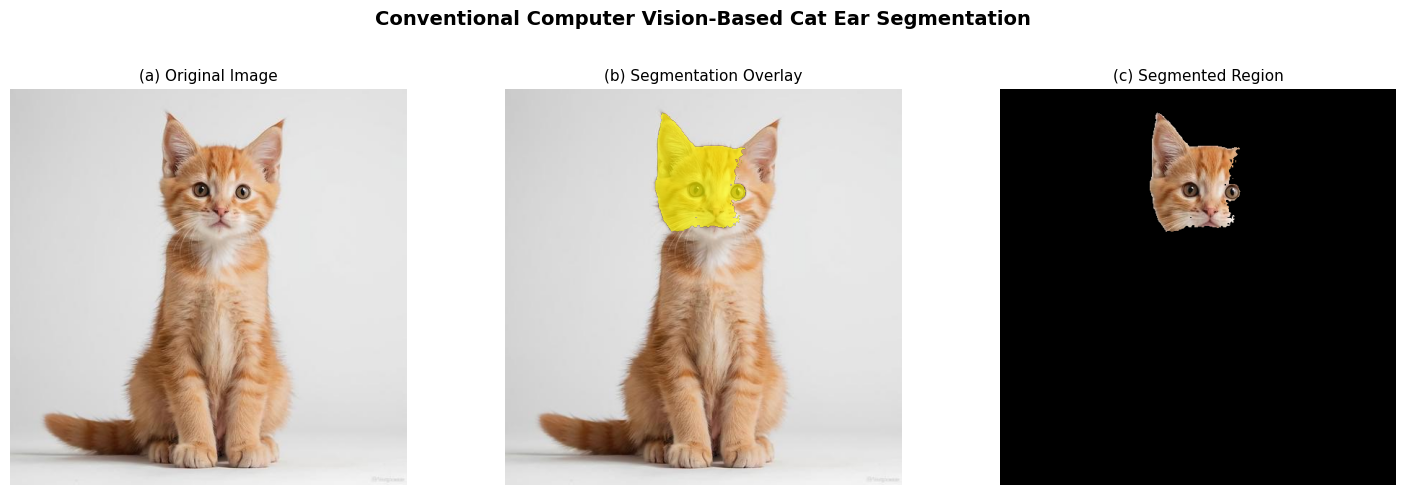

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/results/report_figures/Figure_1_Conventional_CV_Segmentation.png


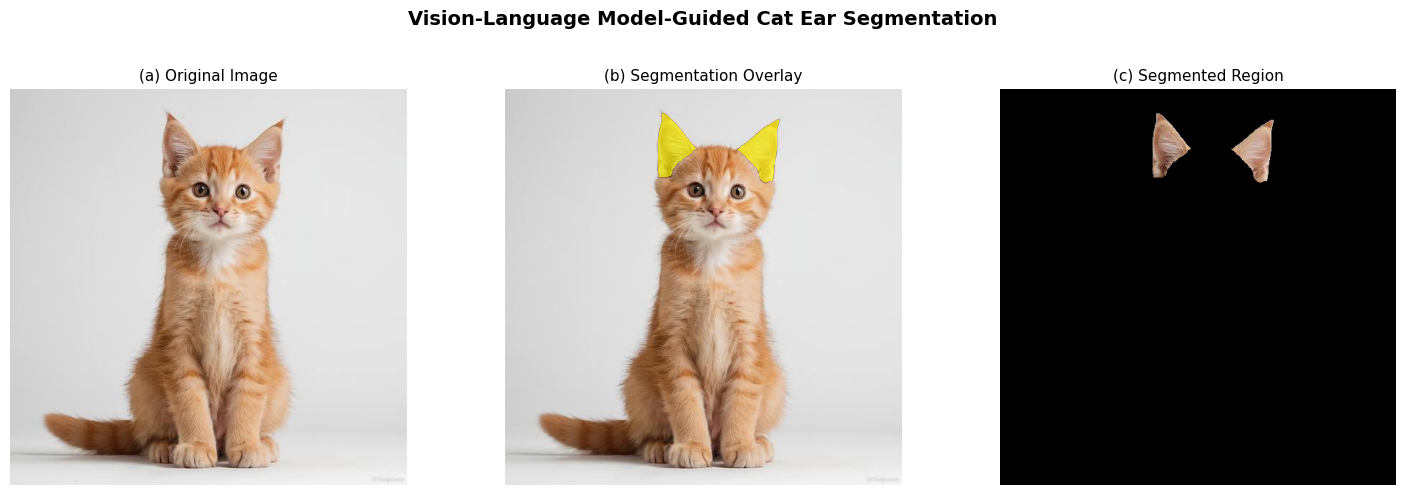

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/results/report_figures/Figure_2_VLM_Guided_Segmentation.png

Both figures generated and saved at 300 DPI.
Output directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/results/report_figures


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Original image
original = np.array(image.convert("RGB"))

# Existing segmentation masks
part_a_mask = np.asarray(predicted_mask).squeeze() > 0
part_b_mask = np.asarray(vlm_mask).squeeze() > 0

# Output directory
figure_dir = PROJECT_DIR / "results" / "report_figures"
figure_dir.mkdir(parents=True, exist_ok=True)

def create_report_figure(mask, title, filename):
    mask = np.asarray(mask).squeeze().astype(bool)

    # Isolate segmented region
    isolated = original.copy()
    isolated[~mask] = 0

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # (a) Original image
    axes[0].imshow(original)
    axes[0].set_title("(a) Original Image", fontsize=11)

    # (b) Segmentation overlay
    axes[1].imshow(original)
    axes[1].imshow(
        np.ma.masked_where(~mask, mask),
        cmap="spring",
        alpha=0.65,
        vmin=0,
        vmax=1
    )
    axes[1].set_title("(b) Segmentation Overlay", fontsize=11)

    # (c) Isolated segmented region
    axes[2].imshow(isolated)
    axes[2].set_title("(c) Segmented Region", fontsize=11)

    for ax in axes:
        ax.axis("off")

    # Formal academic figure title
    fig.suptitle(
        title,
        fontsize=14,
        fontweight="bold",
        y=0.98
    )

    fig.tight_layout(rect=[0, 0, 1, 0.92])

    save_path = figure_dir / filename
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")

# Figure 1
create_report_figure(
    part_a_mask,
    "Conventional Computer Vision-Based Cat Ear Segmentation",
    "Figure_1_Conventional_CV_Segmentation.png"
)

# Figure 2
create_report_figure(
    part_b_mask,
    "Vision-Language Model-Guided Cat Ear Segmentation",
    "Figure_2_VLM_Guided_Segmentation.png"
)

print("\nBoth figures generated and saved at 300 DPI.")
print("Output directory:", figure_dir)


#Compare segmentation statistics

In [ ]:

import numpy as np
import pandas as pd

# Existing segmentation masks
mask_a = np.asarray(predicted_mask).squeeze() > 0
mask_b = np.asarray(vlm_mask).squeeze() > 0

total_pixels = mask_a.size

# Calculate basic segmentation statistics
comparison_data = []

for method, mask in [
    ("Conventional Computer Vision", mask_a),
    ("VLM-Guided Segmentation", mask_b)
]:
    foreground_pixels = int(mask.sum())

    comparison_data.append({
        "Method": method,
        "Image Dimensions": f"{mask.shape[1]} x {mask.shape[0]}",
        "Foreground Pixels": foreground_pixels,
        "Foreground Area (%)": round(
            foreground_pixels / total_pixels * 100, 2
        )
    })

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

# Save the comparison table
comparison_dir = PROJECT_DIR / "results" / "comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

csv_path = comparison_dir / "segmentation_statistics.csv"
comparison_df.to_csv(csv_path, index=False)

print("Comparison statistics saved to:", csv_path)


,Method,Image Dimensions,Foreground Pixels,Foreground Area (%)
0,Conventional Computer Vision,550 x 550,13837,4.57
1,VLM-Guided Segmentation,550 x 550,5368,1.77


Comparison statistics saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/results/comparison/segmentation_statistics.csv


#Create a visual comparison figure

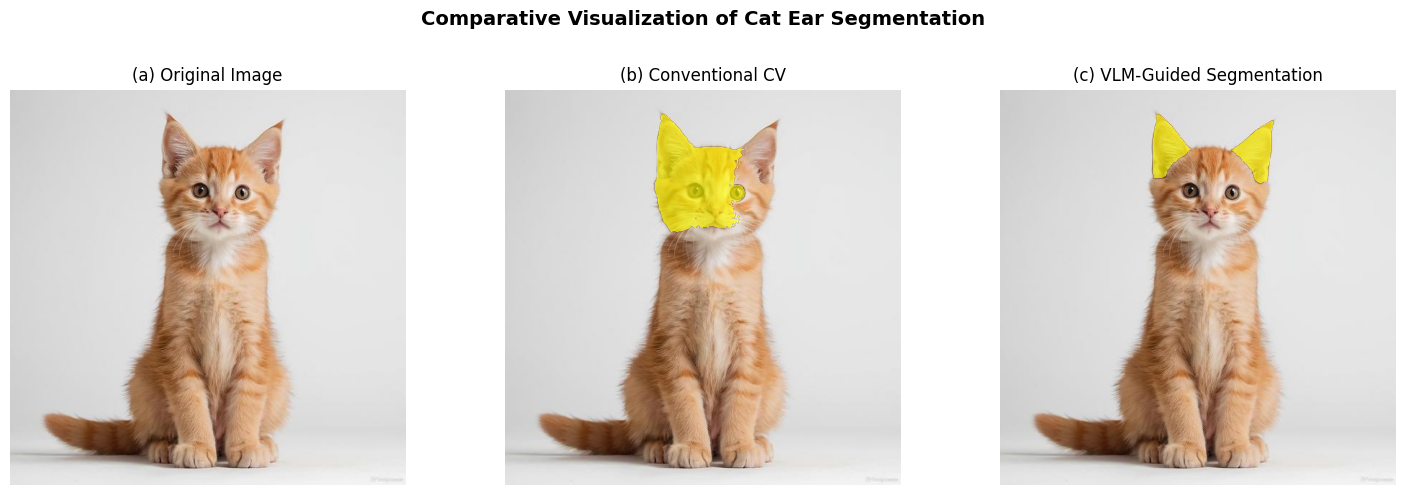

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/results/comparison/Comparative_Cat_Ear_Segmentation.png


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

original = np.array(image.convert("RGB"))

mask_a = np.asarray(predicted_mask).squeeze() > 0
mask_b = np.asarray(vlm_mask).squeeze() > 0

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original image
axes[0].imshow(original)
axes[0].set_title("(a) Original Image")

# Conventional CV overlay
axes[1].imshow(original)
axes[1].imshow(
    np.ma.masked_where(~mask_a, mask_a),
    cmap="spring",
    alpha=0.65,
    vmin=0,
    vmax=1
)
axes[1].set_title("(b) Conventional CV")

# VLM-guided overlay
axes[2].imshow(original)
axes[2].imshow(
    np.ma.masked_where(~mask_b, mask_b),
    cmap="spring",
    alpha=0.65,
    vmin=0,
    vmax=1
)
axes[2].set_title("(c) VLM-Guided Segmentation")

for ax in axes:
    ax.axis("off")

fig.suptitle(
    "Comparative Visualization of Cat Ear Segmentation",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.92])

comparison_dir = PROJECT_DIR / "results" / "comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

comparison_figure_path = (
    comparison_dir / "Comparative_Cat_Ear_Segmentation.png"
)

plt.savefig(comparison_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", comparison_figure_path)


#Install annotation tool

In [ ]:
%pip install -q labelme

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 836.5/836.5 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 65.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 577.7/577.7 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.2/59.2 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.3/84.3 MB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.7/116.7 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 279.3/279.3 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 995.9/99

#Save the image for annotation

In [ ]:
from pathlib import Path

annotation_dir = PROJECT_DIR / "annotations"
annotation_dir.mkdir(parents=True, exist_ok=True)

annotation_image_path = annotation_dir / "cat_for_annotation.jpg"
image.convert("RGB").save(annotation_image_path)

print("Image saved for annotation:")
print(annotation_image_path)


Image saved for annotation:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/annotations/cat_for_annotation.jpg


#Install the annotation library

In [ ]:
%pip install -q ipympl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 33.8 MB/s eta 0:00:00


#Enable interactive annotation


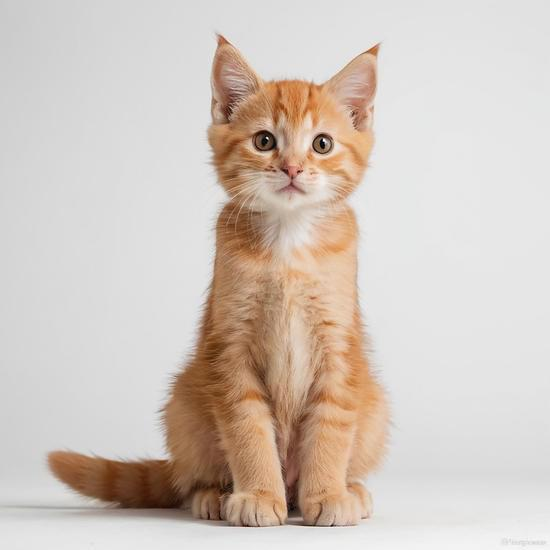

In [ ]:

from IPython.display import HTML, display
from pathlib import Path
import base64
import io

# Convert the original image to a base64 string
buffer = io.BytesIO()
image.convert("RGB").save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = r"""
<div style="font-family:Arial,sans-serif">
  <p>Click around each ear to draw a polygon. Click the first point
  again to close a polygon. Draw both ears, then click Save Annotation.</p>
  <canvas id="canvas" width="550" height="550"
          style="max-width:100%;border:1px solid #888;cursor:crosshair"></canvas>
  <br>
  <button onclick="undoPoint()">Undo last point</button>
  <button onclick="finishPolygon()">Finish current polygon</button>
  <button onclick="saveAnnotation()">Save Annotation</button>
  <button onclick="resetAnnotation()">Reset</button>
  <p id="status">Points: 0 | Completed polygons: 0</p>
  <textarea id="annotationJSON" style="width:100%;height:100px"
            placeholder="Saved annotation JSON will appear here"></textarea>
</div>
<script>
const canvas = document.getElementById('canvas');
const ctx = canvas.getContext('2d');
const statusEl = document.getElementById('status');
const output = document.getElementById('annotationJSON');
const img = new Image();
img.src = 'data:image/png;base64,IMAGE_BASE64_PLACEHOLDER';
let current = [];
let polygons = [];

function draw() {
  ctx.clearRect(0,0,550,550);
  ctx.drawImage(img,0,0,550,550);
  polygons.forEach(poly => drawPoly(poly, true));
  drawPoly(current, false);
  statusEl.textContent =
    'Points: ' + current.length + ' | Completed polygons: ' + polygons.length;
}
function drawPoly(poly, closed) {
  if (!poly.length) return;
  ctx.beginPath();
  ctx.moveTo(poly[0][0],poly[0][1]);
  poly.slice(1).forEach(p => ctx.lineTo(p[0],p[1]));
  if (closed) ctx.closePath();
  ctx.strokeStyle = closed ? '#00ff00' : '#ff3030';
  ctx.lineWidth = 2;
  ctx.stroke();
  poly.forEach(p => {
    ctx.beginPath(); ctx.arc(p[0],p[1],3,0,Math.PI*2);
    ctx.fillStyle = '#ffff00'; ctx.fill();
  });
}
canvas.addEventListener('click', e => {
  const r = canvas.getBoundingClientRect();
  current.push([
    (e.clientX-r.left)*550/r.width,
    (e.clientY-r.top)*550/r.height
  ]);
  draw();
});
function finishPolygon() {
  if (current.length >= 3) {
    polygons.push(current);
    current = [];
    draw();
  } else {
    alert('A polygon needs at least 3 points.');
  }
}
function undoPoint() { current.pop(); draw(); }
function resetAnnotation() {
  current=[]; polygons=[]; output.value=''; draw();
}
function saveAnnotation() {
  if (current.length >= 3) finishPolygon();
  if (polygons.length < 2) {
    alert('Please annotate both ears as two separate polygons.');
    return;
  }
  output.value = JSON.stringify({
    image_width:550, image_height:550,
    target:'cat ears', polygons:polygons
  }, null, 2);
  statusEl.textContent += ' | Annotation JSON ready to copy.';
}
img.onload = draw;
</script>
"""

html = html.replace("IMAGE_BASE64_PLACEHOLDER", image_b64)
display(HTML(html))


#Save annotation JSON to Google Drive

In [ ]:

import json
from pathlib import Path
from IPython.display import display

import ipywidgets as widgets

annotation_dir = PROJECT_DIR / "annotations"
annotation_dir.mkdir(parents=True, exist_ok=True)

json_input = widgets.Textarea(
    value="",
    placeholder="Paste the complete annotation JSON here...",
    description="JSON:",
    layout=widgets.Layout(width="100%", height="250px")
)

save_button = widgets.Button(
    description="Save JSON to Google Drive",
    button_style="success"
)

output = widgets.Output()

def save_annotation_json(_):
    with output:
        output.clear_output()

        try:
            annotation_data = json.loads(json_input.value)

            if "polygons" not in annotation_data:
                raise ValueError("JSON must contain a 'polygons' field.")

            if len(annotation_data["polygons"]) < 2:
                raise ValueError("Please include polygons for both ears.")

            json_path = annotation_dir / "cat_ears_ground_truth.json"

            with open(json_path, "w", encoding="utf-8") as f:
                json.dump(annotation_data, f, indent=2)

            print("Annotation JSON saved successfully!")
            print("File:", json_path)
            print("Number of polygons:", len(annotation_data["polygons"]))

        except Exception as e:
            print("Could not save annotation:", e)

save_button.on_click(save_annotation_json)

display(json_input, save_button, output)


Textarea(value='', description='JSON:', layout=Layout(height='250px', width='100%'), placeholder='Paste the co…

Button(button_style='success', description='Save JSON to Google Drive', style=ButtonStyle())

Output()

#Create and save the ground-truth mask

Ground-truth mask saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/annotations/cat_ears_ground_truth_mask.png
Mask dimensions: (550, 550)
Foreground pixels: 5155


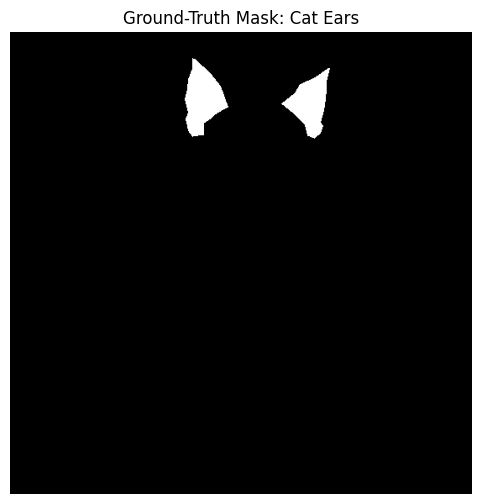

In [ ]:

import json
import numpy as np
from PIL import Image, ImageDraw

json_path = annotation_dir / "cat_ears_ground_truth.json"

with open(json_path, "r", encoding="utf-8") as f:
    annotation_data = json.load(f)

width = annotation_data.get("image_width", 550)
height = annotation_data.get("image_height", 550)

# Create a black mask and fill both ear polygons in white
mask_image = Image.new("L", (width, height), 0)
draw = ImageDraw.Draw(mask_image)

for polygon in annotation_data["polygons"]:
    points = [(float(x), float(y)) for x, y in polygon]
    draw.polygon(points, fill=255)

ground_truth_mask = np.array(mask_image) > 0

mask_path = annotation_dir / "cat_ears_ground_truth_mask.png"
mask_image.save(mask_path)

print("Ground-truth mask saved:", mask_path)
print("Mask dimensions:", ground_truth_mask.shape)
print("Foreground pixels:", int(ground_truth_mask.sum()))

# Display the mask for verification
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.imshow(ground_truth_mask, cmap="gray")
plt.title("Ground-Truth Mask: Cat Ears")
plt.axis("off")
plt.show()

#Calculate IoU and Dice Score

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

# Ground-truth and predicted masks
gt_mask = np.asarray(ground_truth_mask).squeeze().astype(bool)
mask_a = np.asarray(predicted_mask).squeeze() > 0
mask_b = np.asarray(vlm_mask).squeeze() > 0

# Verify that all masks have the same dimensions
assert gt_mask.shape == mask_a.shape == mask_b.shape, (
    f"Mask dimensions do not match: "
    f"GT={gt_mask.shape}, A={mask_a.shape}, B={mask_b.shape}"
)

def calculate_metrics(pred_mask, gt_mask):
    intersection = np.logical_and(pred_mask, gt_mask).sum()
    union = np.logical_or(pred_mask, gt_mask).sum()

    pred_pixels = pred_mask.sum()
    gt_pixels = gt_mask.sum()

    iou = intersection / union if union > 0 else 1.0

    dice_denominator = pred_pixels + gt_pixels
    dice = (
        2 * intersection / dice_denominator
        if dice_denominator > 0 else 1.0
    )

    return {
        "Intersection Pixels": int(intersection),
        "Union Pixels": int(union),
        "Ground-Truth Pixels": int(gt_pixels),
        "Predicted Pixels": int(pred_pixels),
        "IoU (%)": round(float(iou * 100), 2),
        "Dice Score (%)": round(float(dice * 100), 2)
    }

results = []

for method, prediction in [
    ("Conventional Computer Vision", mask_a),
    ("VLM-Guided Segmentation", mask_b)
]:
    metrics = calculate_metrics(prediction, gt_mask)
    metrics["Method"] = method
    results.append(metrics)

metrics_df = pd.DataFrame(results)

# Arrange columns for report presentation
metrics_df = metrics_df[
    [
        "Method",
        "Ground-Truth Pixels",
        "Predicted Pixels",
        "Intersection Pixels",
        "Union Pixels",
        "IoU (%)",
        "Dice Score (%)"
    ]
]

display(metrics_df)

# Save evaluation results
comparison_dir = PROJECT_DIR / "results" / "comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

metrics_path = comparison_dir / "iou_dice_comparison.csv"
metrics_df.to_csv(metrics_path, index=False)

print("\nEvaluation results saved to:")
print(metrics_path)


,Method,Ground-Truth Pixels,Predicted Pixels,Intersection Pixels,Union Pixels,IoU (%),Dice Score (%)
0,Conventional Computer Vision,5155,13837,2688,16304,16.49,28.31
1,VLM-Guided Segmentation,5155,5368,4909,5614,87.44,93.30



Evaluation results saved to:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/results/comparison/iou_dice_comparison.csv


#Visualize the metric comparison

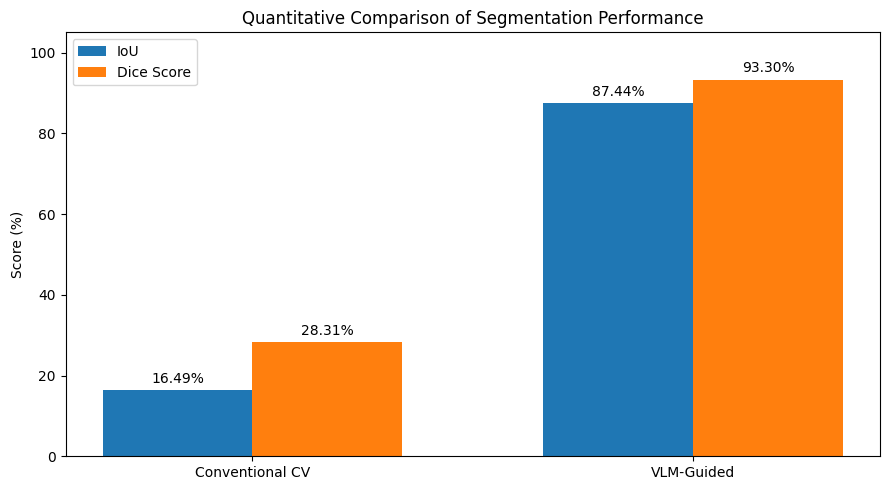

Chart saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/results/comparison/IoU_Dice_Comparison.png


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

methods = ["Conventional CV", "VLM-Guided"]
iou_scores = [16.49, 87.44]
dice_scores = [28.31, 93.30]

x = np.arange(len(methods))
width = 0.34

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, iou_scores, width, label="IoU")
bars2 = ax.bar(x + width/2, dice_scores, width, label="Dice Score")

ax.set_ylabel("Score (%)")
ax.set_title("Quantitative Comparison of Segmentation Performance")
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 105)
ax.legend()
ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()

chart_path = comparison_dir / "IoU_Dice_Comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Chart saved to:", chart_path)


#Create a Gradio interface

In [ ]:

import gradio as gr
import numpy as np
from PIL import Image

def compare_segmentation(input_image, body_part):
    if input_image is None:
        raise gr.Error("Please upload an image.")

    if not body_part.strip():
        raise gr.Error("Please enter a body part, e.g., cat ears.")

    # This demo uses the existing masks for the annotated sample image.
    # It does not yet run inference on arbitrary uploaded images.
    if input_image.size != image.size:
        raise gr.Error(
            "For this initial demo, please use the original annotated "
            "550 x 550 cat image. General-image inference will be added next."
        )

    original = np.array(input_image.convert("RGB"))

    # Existing experiment masks
    mask_a = np.asarray(predicted_mask).squeeze() > 0
    mask_b = np.asarray(vlm_mask).squeeze() > 0

    overlay_a = original.copy()
    overlay_a[mask_a] = (
        0.5 * overlay_a[mask_a] + 0.5 * np.array([0, 255, 0])
    ).astype(np.uint8)

    overlay_b = original.copy()
    overlay_b[mask_b] = (
        0.5 * overlay_b[mask_b] + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    return (
        Image.fromarray(overlay_a),
        Image.fromarray(overlay_b),
        vlm_answer
    )

demo = gr.Interface(
    fn=compare_segmentation,
    inputs=[
        gr.Image(type="pil", label="Upload Cat Image"),
        gr.Textbox(
            label="Target Body Part",
            value="cat ears",
            placeholder="e.g., cat ears"
        )
    ],
    outputs=[
        gr.Image(label="Conventional CV Result"),
        gr.Image(label="VLM-Guided Result"),
        gr.Textbox(label="VLM Description", lines=6)
    ],
    title="Animal Body-Part Segmentation",
    description=(
        "Compare conventional computer vision and VLM-guided "
        "segmentation using the current annotated cat sample."
    )
)

demo.launch(share=False, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

#Build the actual inference pipeline

In [ ]:

from PIL import Image
import numpy as np

def run_conventional_pipeline(input_image, body_part):
    """
    Conventional pipeline:
    YOLO detects the animal, then SAM2 segments the detected object.

    Note: This baseline segments the detected animal, not necessarily
    the requested body part.
    """
    results = yolo_model.predict(
        source=input_image,
        conf=0.25,
        verbose=False
    )

    if not results or results[0].boxes is None or len(results[0].boxes) == 0:
        return None, "No object detected by YOLO."

    result = results[0]
    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    names = result.names

    # Select the highest-confidence detection
    confidences = result.boxes.conf.cpu().numpy()
    best_idx = int(np.argmax(confidences))
    box = boxes[best_idx]

    sam_results = sam_model(
        input_image,
        bboxes=[box.tolist()],
        verbose=False
    )

    if sam_results[0].masks is None:
        return None, "SAM2 did not produce a mask."

    mask = sam_results[0].masks.data[0].cpu().numpy() > 0.5

    original = np.array(input_image.convert("RGB"))
    mask = np.array(
        Image.fromarray(mask.astype(np.uint8) * 255).resize(
            (original.shape[1], original.shape[0])
        )
    ) > 0

    overlay = original.copy()
    overlay[mask] = (
        0.5 * overlay[mask] + 0.5 * np.array([0, 255, 0])
    ).astype(np.uint8)

    detected_class = names[classes[best_idx]]
    message = (
        f"YOLO detected: {detected_class}\n"
        f"Confidence: {confidences[best_idx]:.3f}\n"
        f"Requested body part: {body_part}\n"
        "Limitation: this baseline segments the detected object, "
        "not necessarily the specific body part."
    )

    return Image.fromarray(overlay), message

print("Conventional inference function is ready.")


Conventional inference function is ready.


#Body part locate using VLM and segment using SAM2

In [ ]:

import json
import re
import numpy as np
import torch
from PIL import Image

from qwen_vl_utils import process_vision_info

def run_vlm_pipeline(input_image, body_part):
    if input_image is None:
        raise ValueError("Please upload an image.")

    if not body_part or not body_part.strip():
        raise ValueError("Please enter a body part, e.g., cat ears.")

    input_image = input_image.convert("RGB")
    width, height = input_image.size

    # Step 1: Ask Qwen2.5-VL to localize the requested body part
    prompt = f"""
Analyze this image and locate the following animal body part:
"{body_part}"

Return ONLY one valid JSON object in this exact format:
{{
  "bbox": [x_min, y_min, x_max, y_max],
  "description": "A brief description of the visible body part"
}}

Rules:
- Coordinates must be pixel coordinates in the original image.
- Image width is {width} pixels and image height is {height} pixels.
- bbox must tightly enclose the requested body part.
- If the requested body part is not visible or cannot be identified,
  set bbox to null and explain why in description.
- Do not include Markdown or any text outside the JSON object.
"""

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": input_image},
                {"type": "text", "text": prompt},
            ],
        }
    ]

    text_input = vlm_processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = vlm_processor(
        text=[text_input],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    inputs = inputs.to(vlm_model.device)

    with torch.no_grad():
        generated_ids = vlm_model.generate(
            **inputs,
            max_new_tokens=180
        )

    generated_ids_trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(inputs.input_ids, generated_ids)
    ]

    response = vlm_processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0].strip()

    # Step 2: Parse the VLM's JSON response
    try:
        json_match = re.search(r"\{.*\}", response, re.DOTALL)
        if not json_match:
            raise ValueError("No JSON object found.")

        result = json.loads(json_match.group(0))
        bbox = result.get("bbox")
        description = result.get("description", "No description returned.")

    except Exception as e:
        raise ValueError(
            f"Could not parse the VLM response.\n"
            f"Raw response: {response}\n"
            f"Parsing error: {e}"
        )

    if bbox is None or not isinstance(bbox, list) or len(bbox) != 4:
        raise ValueError(
            f"The VLM could not provide a valid bounding box.\n"
            f"VLM response: {response}"
        )

    # Step 3: Validate and clip the coordinates to the image dimensions
    try:
        x1, y1, x2, y2 = [int(round(float(v))) for v in bbox]
    except (TypeError, ValueError):
        raise ValueError(f"Invalid bounding-box coordinates: {bbox}")

    x1 = max(0, min(x1, width - 1))
    y1 = max(0, min(y1, height - 1))
    x2 = max(0, min(x2, width))
    y2 = max(0, min(y2, height))

    if x2 <= x1 or y2 <= y1:
        raise ValueError(f"The VLM returned an invalid bounding box: {bbox}")

    valid_bbox = [x1, y1, x2, y2]

    # Step 4: Use SAM2 to segment the VLM-localized body part
    sam_results = sam_model(
        input_image,
        bboxes=[valid_bbox],
        verbose=False
    )

    if sam_results[0].masks is None:
        raise ValueError("SAM2 did not produce a segmentation mask.")

    mask = sam_results[0].masks.data[0].cpu().numpy() > 0.5

    # Ensure the mask matches the original image dimensions
    mask_image = Image.fromarray(mask.astype(np.uint8) * 255)
    mask_image = mask_image.resize((width, height), Image.Resampling.NEAREST)
    mask = np.asarray(mask_image) > 0

    # Step 5: Create segmentation overlay
    original = np.asarray(input_image).copy()
    overlay = original.copy()
    overlay[mask] = (
        0.5 * original[mask] + 0.5 * np.array([0, 255, 0])
    ).astype(np.uint8)

    # Step 6: Create an isolated view of the segmented region
    isolated = np.zeros_like(original)
    isolated[mask] = original[mask]

    message = (
        f"Requested body part: {body_part}\n"
        f"VLM bounding box: {valid_bbox}\n"
        f"Image dimensions: {width} × {height}\n\n"
        f"VLM description: {description}\n\n"
        f"Raw VLM response:\n{response}"
    )

    return (
        Image.fromarray(overlay),
        Image.fromarray(isolated),
        message
    )

print("VLM-guided inference function is ready.")


VLM-guided inference function is ready.


#Testing using cat ears

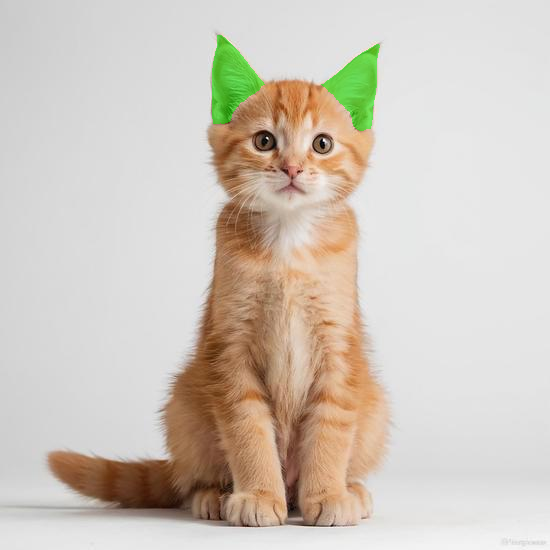

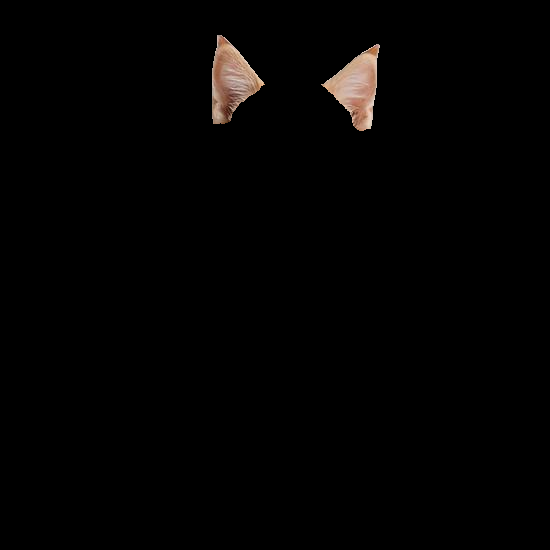

Requested body part: cat ears
VLM bounding box: [214, 33, 387, 136]
Image dimensions: 550 × 550

VLM description: A pair of cat ears.

Raw VLM response:
```json
[
  {
    "bbox": [214, 33, 387, 136],
    "description": "A pair of cat ears."
  }
]
```


In [ ]:
test_image = Image.open(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/data/sample_images/cat.jpg"
).convert("RGB")

test_overlay, test_isolated, test_message = run_vlm_pipeline(
    test_image,
    "cat ears"
)

display(test_overlay)
display(test_isolated)
print(test_message)


#Final Gradio Interface

In [ ]:

import gradio as gr
from PIL import Image

def compare_live_pipelines(input_image, body_part):
    if input_image is None:
        raise gr.Error("Please upload an image.")

    if not body_part or not body_part.strip():
        raise gr.Error("Please enter a body part, e.g., cat ears.")

    # Part A: Conventional YOLO + SAM2
    try:
        conventional_overlay, conventional_message = (
            run_conventional_pipeline(input_image, body_part)
        )

        if conventional_overlay is None:
            conventional_overlay = input_image.convert("RGB")

    except Exception as e:
        conventional_overlay = input_image.convert("RGB")
        conventional_message = f"Conventional pipeline error: {e}"

    # Part B: Qwen2.5-VL + SAM2
    try:
        vlm_overlay, vlm_isolated, vlm_message = run_vlm_pipeline(
            input_image, body_part
        )
    except Exception as e:
        raise gr.Error(f"VLM-guided pipeline error: {e}")

    return (
        conventional_overlay,
        conventional_message,
        vlm_overlay,
        vlm_isolated,
        vlm_message
    )


demo = gr.Interface(
    fn=compare_live_pipelines,
    inputs=[
        gr.Image(type="pil", label="Upload an Image"),
        gr.Textbox(
            label="Target Animal Body Part",
            placeholder="e.g., cat ears, dog nose, bird beak",
            value="cat ears"
        )
    ],
    outputs=[
        gr.Image(type="pil", label="Part A: Conventional Segmentation"),
        gr.Textbox(label="Part A: Detection Details"),
        gr.Image(type="pil", label="Part B: VLM-Guided Segmentation"),
        gr.Image(type="pil", label="Part B: Isolated Region"),
        gr.Textbox(label="Part B: VLM Description and Bounding Box")
    ],
    title="Animal Body-Part Segmentation: Conventional CV vs VLM",
    description=(
        "Compare a conventional YOLO + SAM2 baseline with "
        "Qwen2.5-VL-guided SAM2 segmentation."
    )
)

demo.launch(share=False, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

#Create folder to save gradio test results

In [ ]:

from pathlib import Path

RESULTS_DIR = (
    PROJECT_DIR / "results" / "gradio_tests"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Results folder:", RESULTS_DIR)
print("Folder exists:", RESULTS_DIR.exists())


Results folder: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment13_VLM/results/gradio_tests
Folder exists: True


#Function for save results

In [ ]:

from pathlib import Path
from datetime import datetime
from PIL import Image
import json
import csv

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/"
    "Assignment13_VLM/results/gradio_tests"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def save_gradio_results(
    input_image,
    body_part,
    conventional_overlay,
    conventional_message,
    vlm_overlay,
    vlm_isolated,
    vlm_message
):
    if input_image is None:
        raise ValueError("No input image to save.")

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    test_dir = RESULTS_DIR / f"test_{timestamp}"
    test_dir.mkdir(parents=True, exist_ok=True)

    # Save the original image and generated outputs
    input_image.convert("RGB").save(test_dir / "original_image.png")

    if conventional_overlay is not None:
        conventional_overlay.save(
            test_dir / "conventional_segmentation.png"
        )

    if vlm_overlay is not None:
        vlm_overlay.save(
            test_dir / "vlm_segmentation_overlay.png"
        )

    if vlm_isolated is not None:
        vlm_isolated.save(
            test_dir / "vlm_isolated_region.png"
        )

    # Save detailed text results
    (test_dir / "conventional_details.txt").write_text(
        str(conventional_message), encoding="utf-8"
    )

    (test_dir / "vlm_details.txt").write_text(
        str(vlm_message), encoding="utf-8"
    )

    metadata = {
        "test_id": test_dir.name,
        "prompt": body_part,
        "image_size": list(input_image.size),
        "conventional_output_saved": conventional_overlay is not None,
        "vlm_output_saved": vlm_overlay is not None,
        "vlm_isolated_region_saved": vlm_isolated is not None,
        "conventional_details": str(conventional_message),
        "vlm_details": str(vlm_message)
    }

    (test_dir / "metadata.json").write_text(
        json.dumps(metadata, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    # Append one summary row to a CSV file
    csv_path = RESULTS_DIR / "test_summary.csv"
    write_header = not csv_path.exists()

    with csv_path.open("a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["test_id", "prompt", "image_width", "image_height"]
        )
        if write_header:
            writer.writeheader()

        writer.writerow({
            "test_id": test_dir.name,
            "prompt": body_part,
            "image_width": input_image.width,
            "image_height": input_image.height
        })

    return f"Results saved successfully!\nFolder: {test_dir}"


print("Save-results function is ready.")


Save-results function is ready.


#Updated Gradio interface

In [ ]:

import gradio as gr
from PIL import Image

# Store the latest completed inference results
latest_results = {}

def run_and_store(input_image, body_part):
    if input_image is None:
        raise gr.Error("Please upload an image.")
    if not body_part or not body_part.strip():
        raise gr.Error("Please enter a body part.")

    # Conventional pipeline
    try:
        conventional_overlay, conventional_message = (
            run_conventional_pipeline(input_image, body_part)
        )
        if conventional_overlay is None:
            conventional_overlay = input_image.convert("RGB")
    except Exception as e:
        conventional_overlay = input_image.convert("RGB")
        conventional_message = f"Conventional pipeline error: {e}"

    # VLM-guided pipeline
    try:
        vlm_overlay, vlm_isolated, vlm_message = (
            run_vlm_pipeline(input_image, body_part)
        )
    except Exception as e:
        raise gr.Error(f"VLM pipeline error: {e}")

    latest_results.clear()
    latest_results.update({
        "input_image": input_image.copy(),
        "body_part": body_part,
        "conventional_overlay": conventional_overlay,
        "conventional_message": conventional_message,
        "vlm_overlay": vlm_overlay,
        "vlm_isolated": vlm_isolated,
        "vlm_message": vlm_message
    })

    return (
        conventional_overlay,
        conventional_message,
        vlm_overlay,
        vlm_isolated,
        vlm_message,
        "Inference complete. Click 'Save Results to Google Drive' to save."
    )


def save_latest_results():
    if not latest_results:
        raise gr.Error("Run an image and prompt first.")

    try:
        return save_gradio_results(
            latest_results["input_image"],
            latest_results["body_part"],
            latest_results["conventional_overlay"],
            latest_results["conventional_message"],
            latest_results["vlm_overlay"],
            latest_results["vlm_isolated"],
            latest_results["vlm_message"]
        )
    except Exception as e:
        raise gr.Error(f"Could not save results: {e}")


with gr.Blocks() as demo:
    gr.Markdown("# Animal Body-Part Segmentation")
    gr.Markdown(
        "Compare conventional YOLO + SAM2 with "
        "Qwen2.5-VL-guided SAM2."
    )

    with gr.Row():
        input_image = gr.Image(type="pil", label="Upload Image")
        body_part = gr.Textbox(
            label="Target Body Part",
            value="cat ears",
            placeholder="e.g., dog nose"
        )

    run_button = gr.Button("Submit", variant="primary")
    status = gr.Textbox(label="Status", interactive=False)

    with gr.Row():
        conventional_output = gr.Image(
            label="Part A: Conventional Segmentation"
        )
        vlm_output = gr.Image(
            label="Part B: VLM-Guided Segmentation"
        )

    with gr.Row():
        conventional_details = gr.Textbox(
            label="Part A Details", lines=5
        )
        vlm_isolated_output = gr.Image(
            label="Part B: Isolated Region"
        )

    vlm_details = gr.Textbox(
        label="Part B: VLM Description and Bounding Box",
        lines=8
    )

    save_button = gr.Button("Save Results to Google Drive")
    save_status = gr.Textbox(label="Save Status", interactive=False)

    run_button.click(
        fn=run_and_store,
        inputs=[input_image, body_part],
        outputs=[
            conventional_output,
            conventional_details,
            vlm_output,
            vlm_isolated_output,
            vlm_details,
            status
        ]
    )

    save_button.click(
        fn=save_latest_results,
        inputs=[],
        outputs=[save_status]
    )

demo.launch(share=False, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>